# Insurance Charges Prediction

EDA and a simple Multiple Linear Regression model using the insurance dataset.

## Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

%matplotlib inline

## Load and review the dataset

In [2]:
df = pd.read_csv("insurance.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
df.shape

(1338, 7)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.207025,14.049960,18.0000,27.00000,39.000,51.000000,64.00000
bmi,1338.0,30.663397,6.098187,15.9600,26.29625,30.400,34.693750,53.13000
children,1338.0,1.094918,1.205493,0.0000,0.00000,1.000,2.000000,5.00000
charges,1338.0,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


## Data quality checks

In [6]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(1)

In [8]:
df = df.drop_duplicates().copy()
df.shape

(1337, 7)

## Exploratory Data Analysis

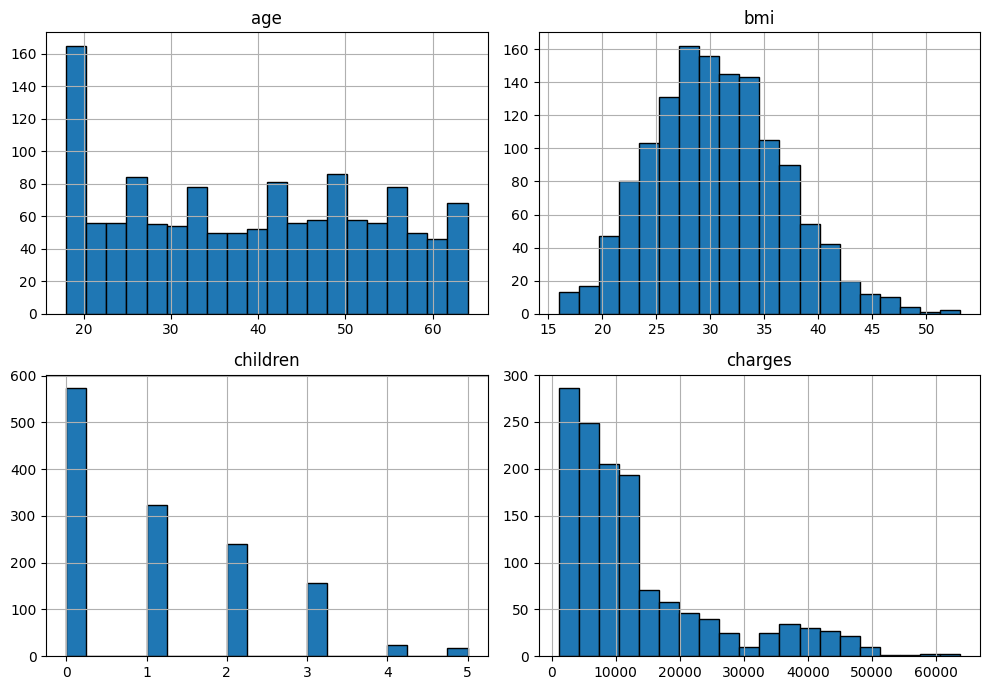

In [9]:
df.hist(figsize=(10, 7), bins=20, edgecolor="black")
plt.tight_layout()
plt.show()

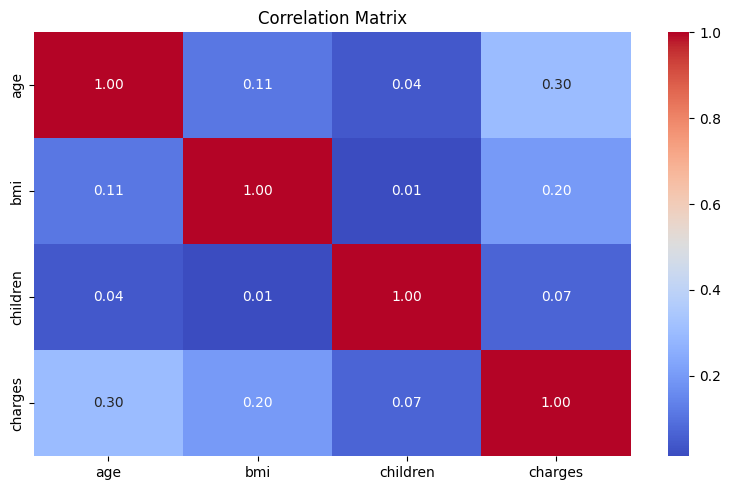

In [10]:
plt.figure(figsize=(8, 5))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

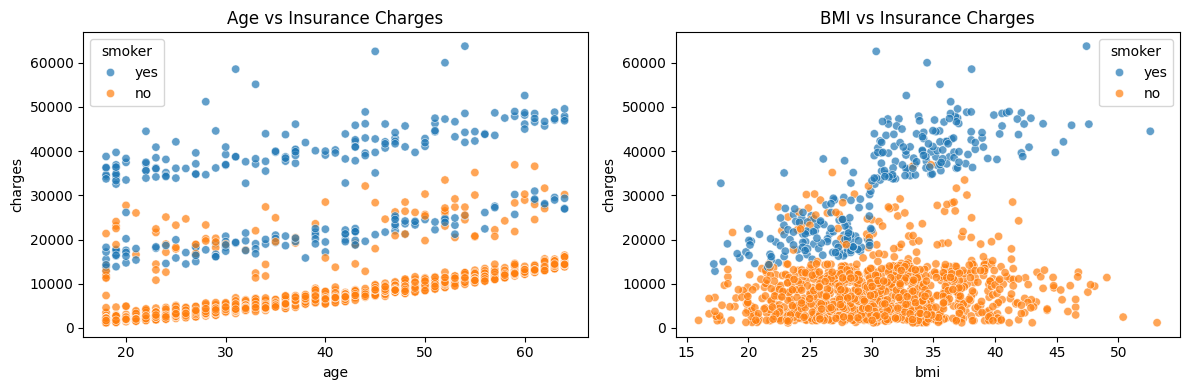

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=df, x="age", y="charges", hue="smoker", alpha=0.7, ax=axes[0])
axes[0].set_title("Age vs Insurance Charges")
sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker", alpha=0.7, ax=axes[1])
axes[1].set_title("BMI vs Insurance Charges")
plt.tight_layout()
plt.show()

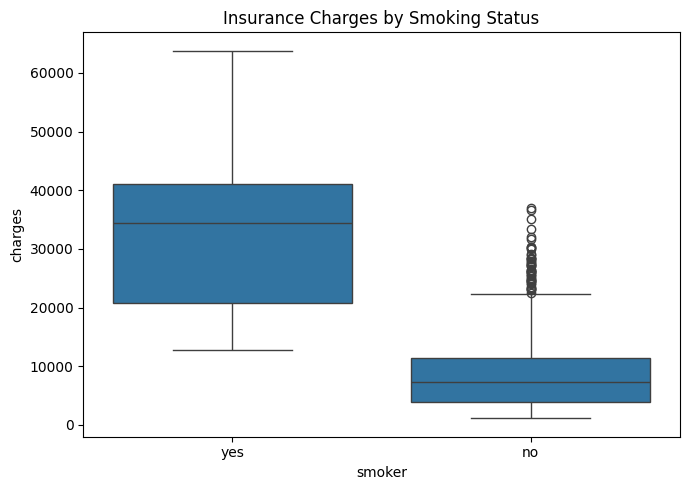

In [12]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="smoker", y="charges")
plt.title("Insurance Charges by Smoking Status")
plt.tight_layout()
plt.show()

## Outlier check using the IQR method

The IQR method flags values outside Q1 − 1.5 × IQR and Q3 + 1.5 × IQR. Check numeric columns; cap input features only. The target (`charges`) is kept unchanged so its actual values remain available for model training and evaluation.

In [13]:
numeric_cols = ["age", "bmi", "children"]
outlier_summary = []

for col in numeric_cols + ["charges"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR
    count = ((df[col] < lower_limit) | (df[col] > upper_limit)).sum()
    outlier_summary.append([col, Q1, Q3, lower_limit, upper_limit, count])

outlier_summary = pd.DataFrame(
    outlier_summary,
    columns=["Feature", "Q1", "Q3", "Lower Limit", "Upper Limit", "Outlier Count"]
)
outlier_summary

,Feature,Q1,Q3,Lower Limit,Upper Limit,Outlier Count
0,age,27.000,51.00000,-9.000000,87.000000,0
1,bmi,26.290,34.70000,13.675000,47.315000,9
2,children,0.000,2.00000,-3.000000,5.000000,0
3,charges,4746.344,16657.71745,-13120.716175,34524.777625,139


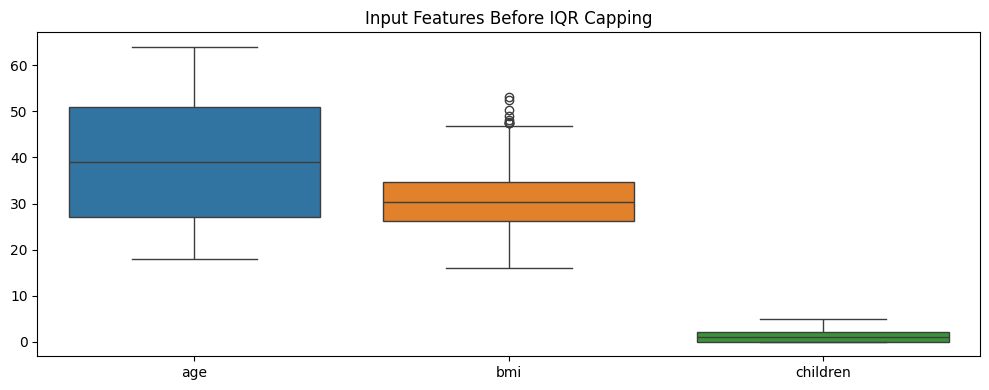

In [14]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=df[numeric_cols])
plt.title("Input Features Before IQR Capping")
plt.tight_layout()
plt.show()

Potential outliers are not always errors. Cap outliers in the numeric input features and retain all remaining observations. `charges` is not capped because it is the prediction target.

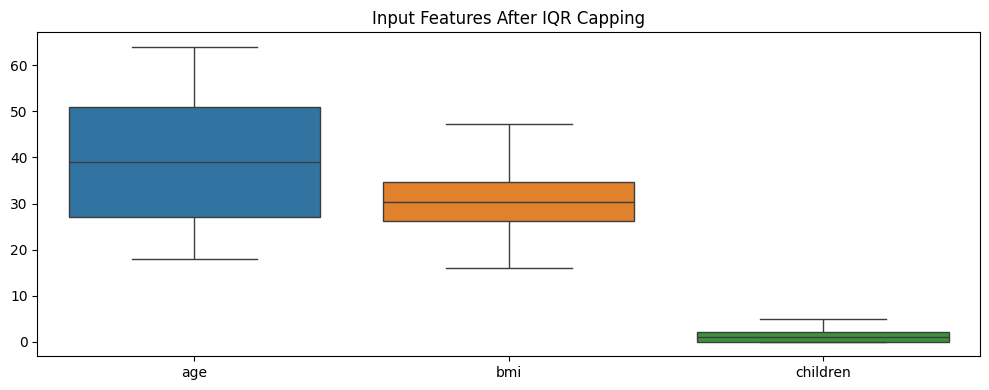

In [15]:
df_model = df.copy()

for col in numeric_cols:
    Q1 = df_model[col].quantile(0.25)
    Q3 = df_model[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR
    df_model[col] = df_model[col].clip(lower=lower_limit, upper=upper_limit)

plt.figure(figsize=(10, 4))
sns.boxplot(data=df_model[numeric_cols])
plt.title("Input Features After IQR Capping")
plt.tight_layout()
plt.show()

## Prepare the data and train the model

In [16]:
X = df_model.drop(columns="charges")
X = pd.get_dummies(X, drop_first=True, dtype=int)
y = df_model["charges"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

regression_model = LinearRegression()
regression_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


## Predict insurance charges

In [17]:
y_pred = regression_model.predict(X_test)

## Evaluate model performance

In [18]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5

print("R² Score:", round(r2, 4))
print("Mean Absolute Error:", round(mae, 2))
print("Root Mean Squared Error:", round(rmse, 2))

R² Score: 0.8071
Mean Absolute Error: 4181.9
Root Mean Squared Error: 5954.23


In [19]:
pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": regression_model.coef_
}).sort_values("Coefficient", ascending=False)

,Feature,Coefficient
4,smoker_yes,23080.401255
2,children,531.431718
1,bmi,321.831944
0,age,247.724818
3,sex_male,-94.095355
5,region_northwest,-393.032595
7,region_southwest,-663.623783
6,region_southeast,-834.370982


## Actual vs Predicted Charges

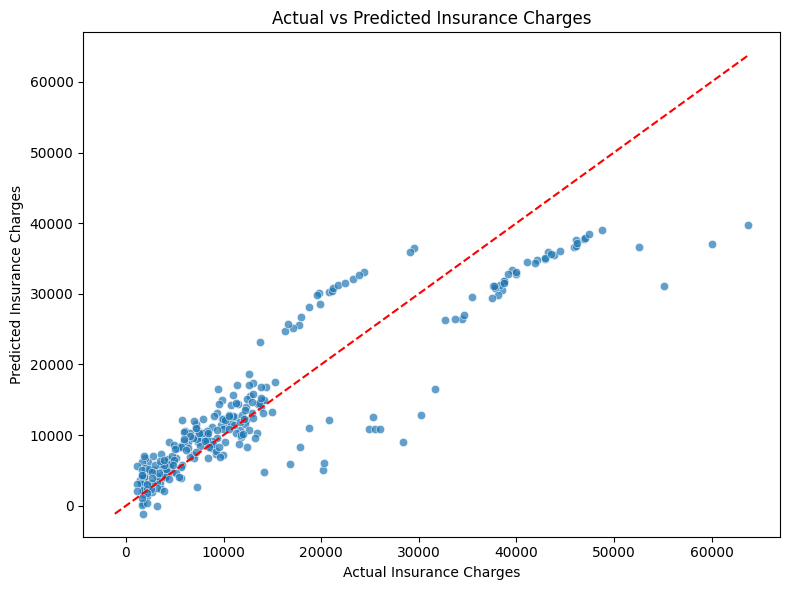

In [20]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.7)
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], color="red", linestyle="--")
plt.xlabel("Actual Insurance Charges")
plt.ylabel("Predicted Insurance Charges")
plt.title("Actual vs Predicted Insurance Charges")
plt.tight_layout()
plt.show()

## Observation

In [21]:
corr_age = df_model["age"].corr(df_model["charges"])
corr_bmi = df_model["bmi"].corr(df_model["charges"])
smoker_means = df_model.groupby("smoker")["charges"].mean()
smoker_ratio = smoker_means.get("yes", np.nan) / smoker_means.get("no", np.nan)

observation = f"""
<b>Observations</b><br>
• After removing duplicate rows, the dataset contains {len(df_model)} records and {df_model.shape[1]} columns.<br>
• Missing values remaining: {int(df_model.isnull().sum().sum())}.<br>
• Age has a correlation of {corr_age:.2f} with charges; BMI has a correlation of {corr_bmi:.2f}.<br>
• Average charges for smokers are about {smoker_ratio:.1f} times the average for non-smokers.<br>
• IQR capping was applied to age, BMI, and children. The target charges was not capped.<br>
• On the 20% test set, R² = {r2:.3f}, MAE = {mae:.2f}, and RMSE = {rmse:.2f}.<br>
• This is a simple baseline model; its predictions may miss nonlinear patterns and interactions.
"""
display(HTML(f'<div style="border:1px solid #888; border-radius:8px; padding:14px; background:#f7f7f7; color:#222;">{observation}</div>'))